In [1]:
# geopandas 处理深圳栅格数据并制图练习
# 完成时间：2026-7-8~2026-7-11
# 练习内容：使用python的geopandas包把连续的深圳地理空间，切分成栅格，对出租车OD数据进行栅格对应，完成统计和可视化

读取shp文件

In [2]:
"""
GeoPandas 是 Python 生态中最主流的地理空间矢量数据处理库，它在 Pandas 的基础上扩展了空间数据处理能力，将表格型属性数据与几何要素（点、线、面）无缝结合
让空间数据的批量处理、分析、可视化可以像操作普通 DataFrame 一样简单高效。
Shapely 是 Python 生态中最主流的平面几何运算库，专门用于处理点、线、面等矢量几何对象支持：几何对象的创建、编辑、坐标提取;
空间关系判断（包含、相交、相邻、距离计算等）;空间运算（交集、并集、差集、缓冲区、面积 / 周长计算等）;它不负责地图投影、坐标系转换，专注于纯几何层面的计算
Fiona负责矢量空间文件的读写（支持 shp、GeoJSON、GPKG 等格式），PyProj：负责地图投影与坐标系转换
"""

'\nGeoPandas 是 Python 生态中最主流的地理空间矢量数据处理库，它在 Pandas 的基础上扩展了空间数据处理能力，将表格型属性数据与几何要素（点、线、面）无缝结合\n让空间数据的批量处理、分析、可视化可以像操作普通 DataFrame 一样简单高效。\nShapely 是 Python 生态中最主流的平面几何运算库，专门用于处理点、线、面等矢量几何对象支持：几何对象的创建、编辑、坐标提取;\n空间关系判断（包含、相交、相邻、距离计算等）;空间运算（交集、并集、差集、缓冲区、面积 / 周长计算等）;它不负责地图投影、坐标系转换，专注于纯几何层面的计算\nFiona负责矢量空间文件的读写（支持 shp、GeoJSON、GPKG 等格式），PyProj：负责地图投影与坐标系转换\n'

<Axes: >

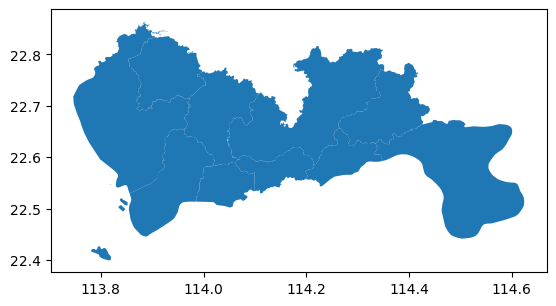

In [3]:
# 导入必要的包
import pandas as pd
import numpy as np

# 绘制图用的包
import matplotlib as mpl
import matplotlib.pyplot as plt

# geopandas包
import geopandas as gpd

# shapely包
from shapely.geometry import Point,Polygon,shape

# 读取shapefile文件
shp = r'E:/GIS_Learning/data/sz.shp'
sz = gpd.GeoDataFrame.from_file(shp, encoding='utf-8')

# 绘制看看长什么样
sz.plot()

In [4]:
# geopandas的格式，就是类似pandas的表格，但是加上一列geometry，记录了每行记录的地理信息
type(sz)

geopandas.geodataframe.GeoDataFrame

In [5]:
# 每行记录的geometry，它的格式是shapely包的Polygon
sz.head(5)

,centroid_x,centroid_y,qh,geometry
0,114.143157,22.577605,罗湖,"POLYGON ((114.1 22.534, 114.1 22.535, 114.1 22..."
1,114.041535,22.546180,福田,"POLYGON ((113.99 22.513, 113.99 22.523, 113.99..."
2,114.270206,22.596432,盐田,"POLYGON ((114.23 22.543, 114.23 22.544, 114.23..."
3,113.851387,22.679120,宝安,"MULTIPOLYGON (((113.82 22.547, 113.82 22.547, ..."
4,113.926290,22.766157,光明,"POLYGON ((113.99 22.803, 113.99 22.803, 113.99..."


In [6]:
type(sz['geometry'].iloc[0])
# polygon指多边形

shapely.geometry.polygon.Polygon

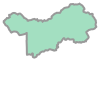

In [7]:
sz['geometry'].iloc[0] # 自带显示功能

<Axes: >

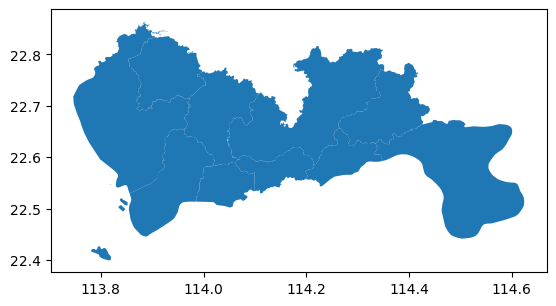

In [8]:
sz.plot()

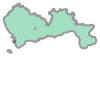

In [9]:
# 用unary_all()可以将一个geopandas的所有记录合并为一个图形，合并出来的结果是Polygon
sz.union_all()

栅格化

In [10]:
# 单点栅格匹配的核心算法：输入一个经纬度坐标，计算它落在哪个 500 米见方的栅格内（输出栅格编号），同时计算该栅格的中心点经纬度。

In [11]:
# 写一段够能直接批量算出来一批经纬度的栅格编号的代码
# 栅格化代码
import math
#定义一个测试栅格划的经纬度（先拿单个点演示栅格化的完整计算逻辑，验证算法正确性）
testlon = 114
testlat = 22.5

# 划定栅格划分范围（所有栅格只在这个范围内生成，后续超出这个范围的 OD 数据会被直接过滤，减少无效计算）
lon1 = 113.75194
lon2 = 114.624187
lat1 = 22.447837
lat2 = 22.864748

# 取纬度最小值作为纬度方向的起始边（最南边），取经度最小值作为经度方向的起始边（最西边）
# 栅格编号规则是从西南角（左下角）开始，从左到右、从下到上递增，用最小值作为编号起点，能保证所有栅格编号都是正整数
latStart = min(lat1, lat2);
lonStart = min(lon1, lon2);

# 定义栅格大小(单位m) 500 米是城市交通研究常用的栅格尺度
accuracy = 500;

# 计算栅格的经纬度增加量大小▲Lon和▲Lat（公式）
deltaLon = accuracy * 360 / (2 * math.pi * 6371004 * math.cos((lat1 + lat2) * math.pi / 360));
deltaLat = accuracy * 360 / (2 * math.pi * 6371004);

# 计算栅格的经纬度编号
LONCOL=divmod(float(testlon) - (lonStart - deltaLon / 2) , deltaLon)[0]
LATCOL=divmod(float(testlat) - (latStart - deltaLat / 2) , deltaLat)[0]
# divmod(a, b)是 Python 内置函数，返回(a//b, a%b)元组

# 计算栅格的中心点经纬度
HBLON = LONCOL*deltaLon + (lonStart - deltaLon / 2) # 格子编号*格子宽+起始横坐标-半个格子宽=格子中心横坐标
HBLAT = LATCOL*deltaLat + (latStart - deltaLat / 2)
# lonStart - deltaLon / 2 是整个栅格体系的最左边界
# LONCOL*deltaLon 是从最左边界到当前栅格左边缘的总宽度

# 把算好的东西print出来看看
LONCOL,LATCOL,HBLON,HBLAT,deltaLon,deltaLat

(51.0,
 12.0,
 113.99800701150498,
 22.499547959873865,
 0.004872614089207591,
 0.004496605206422906)

In [12]:
# 基于已算出的栅格中心点与栅格步长，构造出对应栅格的正方形面要素（shapely Polygon 对象）

In [13]:
# 生成这些栅格的geopandas数据
from shapely.geometry import Point,Polygon,shape
# Point是 Shapely 中表示零维点要素的类，用于实例化一个坐标点对象，Point(x, y)，对应地理场景中就是Point(经度, 纬度)
# Polygon是 Shapely 中表示二维面要素的类，传入按顺时针 / 逆时针顺序排列的边界坐标点序列，会自动闭合多边形
# shape是一个转换函数（不是类），核心作用是将符合 GeoJSON 规范的几何字典（dict）转换为 Shapely 可操作的几何对象
Polygon([(HBLON+deltaLon/2,HBLAT-deltaLat/2),
        (HBLON+deltaLon/2,HBLAT+deltaLat/2),
        (HBLON-deltaLon/2,HBLAT+deltaLat/2),
        (HBLON-deltaLon/2,HBLAT-deltaLat/2)])
# 已经算出了栅格的中心点(HBLON, HBLAT)，以及单个栅格的经度宽度deltaLon、纬度高度deltaLat。栅格的四条边界可以通过「中心点 ± 半格尺寸」直接推导
"""
东边界（右）：HBLON + deltaLon/2（中心点经度 + 半格宽度）
西边界（左）：HBLON - deltaLon/2（中心点经度 - 半格宽度）
北边界（上）：HBLAT + deltaLat/2（中心点纬度 + 半格高度）
南边界（下）：HBLAT - deltaLat/2（中心点纬度 - 半格高度）
列表里的 4 个坐标按顺时针顺序依次连接，Polygon会自动闭合首尾点，形成完整的矩形面
"""

'\n东边界（右）：HBLON + deltaLon/2（中心点经度 + 半格宽度）\n西边界（左）：HBLON - deltaLon/2（中心点经度 - 半格宽度）\n北边界（上）：HBLAT + deltaLat/2（中心点纬度 + 半格高度）\n南边界（下）：HBLAT - deltaLat/2（中心点纬度 - 半格高度）\n列表里的 4 个坐标按顺时针顺序依次连接，Polygon会自动闭合首尾点，形成完整的矩形面\n'

In [14]:
# 批量生成覆盖研究区的 500 米规则栅格网，构建带空间几何与属性信息的 GeoDataFrame

<Axes: >

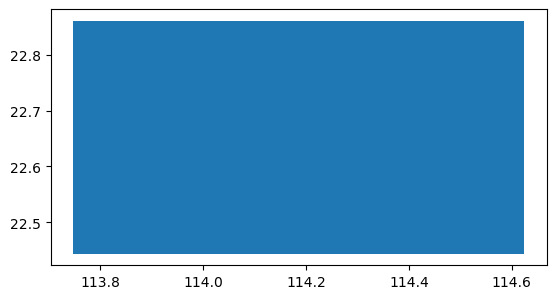

In [15]:
# 计算获取出整个深圳的栅格
import pandas as pd
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
import geopandas
from shapely.geometry import Point,Polygon,shape


# 定义空的geopandas表
data = geopandas.GeoDataFrame()

# 定义空的list，后面循环一次就往里面加东西
LONCOL = []
LATCOL = []
geometry = []
HBLON1 = []
HBLAT1 = []

# 计算总共要生成多少个栅格（lon2-lon1 是研究区的总经度跨度，除以单个栅格的经度宽度deltaLon，得到理论栅格数量）
# lon方向是lonsnum个栅格
lonsnum = int((lon2-lon1)/deltaLon)+1
# lat方向是latsnum个栅格
latsnum = int((lat2-lat1)/deltaLat)+1
# +1 是关键细节：比如从第 0 格到第 2 格，跨度是 2 格宽度，实际有 3 个栅格（0、1、2），+1 才能把首尾两个边界的栅格都包含进去，避免少算一行 / 一列。

# 核心部分，通过两层循环遍历所有栅格，逐个计算中心点、生成多边形并存入列表
for i in range(lonsnum):
    for j in range(latsnum):
        # 计算编号为(i,j)的栅格的中心点经纬度
        HBLON = i*deltaLon + (lonStart - deltaLon / 2)
        HBLAT = j*deltaLat + (latStart - deltaLat / 2)
        # 把生成的数据都加入到前面定义的空list里面
        LONCOL.append(i)
        LATCOL.append(j)
        HBLON1.append(HBLON)
        HBLAT1.append(HBLAT)
        
        # 生成栅格的Polygon形状
        # 计算右侧相邻栅格的中心点经度、上方相邻栅格的中心点纬度
        """
        核心设计原因：如果每个栅格都用「自身中心点 + 半个栅格宽度」来计算右边界，浮点数多次计算会产生微小的累计误差，导致相邻两个栅格的公共边界坐标出现极小数值差异，
        可视化时就会出现肉眼可见的细缝。而用「右侧栅格的中心点 - 半个栅格宽度」来计算当前栅格的右边界，和右侧栅格自己的左边界是同一个公式算出来的同一个值，可实现无缝拼接
        """
        HBLON_1 = (i+1)*deltaLon + (lonStart - deltaLon / 2)
        HBLAT_1 = (j+1)*deltaLat + (latStart - deltaLat / 2)

        # 构造当前栅格的正方形多边形，按顺时针顺序定义四个顶点
        geometry.append(Polygon([
        (HBLON-deltaLon/2,HBLAT-deltaLat/2),
        (HBLON_1-deltaLon/2,HBLAT-deltaLat/2),
        (HBLON_1-deltaLon/2,HBLAT_1-deltaLat/2),
        (HBLON-deltaLon/2,HBLAT_1-deltaLat/2)]))
"""
西南角（左下）：当前栅格西边界、南边界
东南角（右下）：右侧栅格西边界（= 当前栅格东边界）、南边界
东北角（右上）：右侧栅格西边界、上方栅格南边界（= 当前栅格北边界）
西北角（左上）：当前栅格西边界、上方栅格南边界
"""

# 组装 GeoDataFrame 并可视化
data = geopandas.GeoDataFrame(
    {
        "LONCOL": LONCOL,
        "LATCOL": LATCOL,
        "HBLON": HBLON1,
        "HBLAT": HBLAT1,
        "geometry": geometry
    },
    crs="EPSG:4326"  # WGS84 世界大地坐标系，也就是我们最常用的「经纬度地理坐标系」
)
data.plot()


<Axes: >

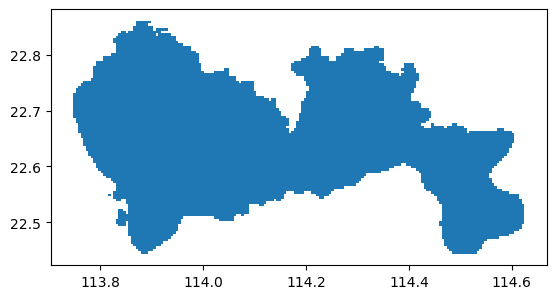

In [16]:
# 从生成的全覆盖矩形栅格里，挑出所有与深圳市行政范围存在空间相交的栅格
grid = data[data.intersects(sz.union_all())]
# sz.union_all() 将 sz 中所有行的几何要素合并成一个统一的几何对象
# data.intersects(sz.union_all()) 对 data 中的每一行网格，执行空间相交判断，返回一个与 data 行数一致的布尔型 Series
grid.plot()

In [17]:
#保存
grid.to_file(r'E:\GIS_Learning\output\grid.gpkg', driver='GPKG')
# .to_file()支持导出 Shapefile、GeoJSON、GPKG 等多种 GIS 矢量格式( 默认ESRI Shapefile 格式)

将数据对应到栅格

In [18]:
# 在上一个项目里，我们已经从出租车的原始数据中提取到了OD并保存
import pandas as pd
TaxiOD = pd.read_csv(r'E:/GIS_Learning/data/TaxiOD.csv')
TaxiOD.columns = ['VehicleNum', 'Stime', 'SLng', 'SLat', 
       'ELng', 'ELat','Etime']
TaxiOD.head(5)

,VehicleNum,Stime,SLng,SLat,ELng,ELat,Etime
0,22223,00:03:23,114.167465,22.562468,114.225235,22.552750,00:10:48
1,22223,00:11:33,114.227150,22.554167,114.229218,22.560217,00:15:19
2,22223,00:17:13,114.231354,22.562166,114.255798,22.590967,00:29:06
3,22223,00:36:45,114.240196,22.563650,114.119965,22.566668,00:54:42
4,22223,01:01:14,114.135414,22.575933,114.166748,22.608267,01:08:17


In [19]:
# 完成出租车 OD 数据的栅格化映射与清洗：把每条 OD 的起点、终点原始经纬度，匹配到预先定义的栅格网格中，得到对应的栅格编号与栅格中心点坐标，
# 同时剔除无效、超范围的脏数据，为后续的栅格统计、OD 可视化做标准化预处理。

In [20]:
# 空值过滤:(原始 OD 数据可能存在脏数据（终点坐标缺失），空值无法参与后续的栅格编号计算，会直接触发报错)
# TaxiOD['ELng'].isnull()：判断终点经度列是否为空值，返回布尔型序列，空值对应True，非空对应False。前缀-是布尔取反运算，最终保留终点经度非空的行。
# .copy()：生成数据的深拷贝，得到独立的新 DataFrame，避免后续修改触发 pandas 的SettingWithCopyWarning，也不会污染原始数据。
TaxiOD = TaxiOD[-TaxiOD['ELng'].isnull()].copy()

# 起点经度栅格列号
TaxiOD['SLONCOL'] = ((TaxiOD['SLng'] - (lonStart - deltaLon / 2))/deltaLon).astype('int')
# lonStart：研究区最左侧的起始经度；deltaLon：单个栅格的经度宽度
# lonStart - deltaLon / 2：将栅格的计算起始点向左偏移半个栅格宽度，让栅格编号对应栅格的中心点，而非栅格的左边界顶点
# 用「起点经度 - 偏移起始点」除以栅格宽度，得到浮点型的位置；.astype('int')对正数做截断取整（等价于向下取整），最终得到整数型的栅格列编号

# 起点纬度栅格行号
TaxiOD['SLATCOL'] = ((TaxiOD['SLat'] - (latStart - deltaLat / 2))/deltaLat).astype('int')
# 逻辑与之前一致latStart是研究区最南侧的起始纬度，deltaLat是单个栅格的纬度高度，计算得到起点对应的纬度方向栅格行号

# 计算起点栅格的中心点经度（和上一步的编号计算完全互逆：栅格列号 × 单格经度宽度 + 起始偏移量 = 该栅格中心点的经度）
TaxiOD['SHBLON'] = TaxiOD['SLONCOL']*deltaLon + (lonStart - deltaLon / 2)
# 后续绘制 OD 线时，不需要用原始的精确经纬度，而是统一用栅格中心点作为起终点。这样所有落在同一个栅格的起点，都会从同一个点出发，实现 OD 的栅格聚合，让可视化结果更规整

#  计算起点栅格的中心点纬度
TaxiOD['SHBLAT'] = TaxiOD['SLATCOL']*deltaLat + (latStart - deltaLat / 2)
# 同理：行号 × 单格纬度高度 + 起始偏移量 = 栅格中心点纬度。和经度配套，得到完整的起点栅格中心点坐标(SHBLON, SHBLAT)

# 计算终点的栅格编号与中心点坐标
TaxiOD['ELONCOL'] = ((TaxiOD['ELng'] - (lonStart - deltaLon / 2))/deltaLon).astype('int')
TaxiOD['ELATCOL'] = ((TaxiOD['ELat'] - (latStart - deltaLat / 2))/deltaLat).astype('int')
TaxiOD['EHBLON'] = TaxiOD['ELONCOL']*deltaLon + (lonStart - deltaLon / 2)
TaxiOD['EHBLAT'] = TaxiOD['ELATCOL']*deltaLat + (latStart - deltaLat / 2)

# 筛选去掉起点终点在同一个格子里的OD
TaxiOD = TaxiOD[-((TaxiOD['SLONCOL']==TaxiOD['ELONCOL'])&(TaxiOD['SLATCOL']==TaxiOD['ELATCOL']))]
# 筛选去掉不在研究范围内的栅格
TaxiOD = TaxiOD[(TaxiOD['SLONCOL']>=0) & (TaxiOD['SLATCOL']>=0) &(TaxiOD['ELONCOL']>=0) & (TaxiOD['ELATCOL']>=0)&
(TaxiOD['SLONCOL']<=lonsnum) & (TaxiOD['SLATCOL']<=latsnum) &(TaxiOD['ELONCOL']<=lonsnum) & (TaxiOD['ELATCOL']<=latsnum)]

TaxiOD.head(5)

,VehicleNum,Stime,SLng,SLat,ELng,ELat,Etime,SLONCOL,SLATCOL,SHBLON,SHBLAT,ELONCOL,ELATCOL,EHBLON,EHBLAT
0,22223,00:03:23,114.167465,22.562468,114.225235,22.552750,00:10:48,85,25,114.163676,22.558004,97,23,114.222147,22.549011
1,22223,00:11:33,114.227150,22.554167,114.229218,22.560217,00:15:19,98,24,114.227020,22.553507,98,25,114.227020,22.558004
2,22223,00:17:13,114.231354,22.562166,114.255798,22.590967,00:29:06,98,25,114.227020,22.558004,103,32,114.251383,22.589480
3,22223,00:36:45,114.240196,22.563650,114.119965,22.566668,00:54:42,100,26,114.236765,22.562500,76,26,114.119822,22.562500
4,22223,01:01:14,114.135414,22.575933,114.166748,22.608267,01:08:17,79,28,114.134440,22.571494,85,36,114.163676,22.607466


集计栅格OD（全天、高峰时段）

In [21]:
# 栅格 OD 数据的聚合统计核心：将单条出租车行程级别的 OD 数据，按照「起点栅格 + 终点栅格」进行分组，
# 统计每一组 OD 对应的总车流量，把数据粒度从 “单条行程” 聚合到 “栅格 OD 对” 级别

In [22]:
OD = TaxiOD.groupby(['SLONCOL','SLATCOL','ELONCOL','ELATCOL'])['VehicleNum'].count().reset_index()

绘制栅格的OD图

In [23]:
# 取出流量最高的前 20 条栅格 OD，计算每条 OD 起点、终点栅格的中心点经纬度坐标**，为后续绘制 OD 连线提供坐标数据

In [24]:
# 提取前 20 条 OD 并生成独立副本
Topod = OD.iloc[:20].copy()
# 先取少量高流量 OD 做绘制演示，图形清晰，方便验证 OD 连线的逻辑是否正确
# .copy()生成独立副本是 Pandas 的规范写法，保证数据安全、消除警告

# 计算起点栅格的中心点经纬度
Topod['SHBLON'] = Topod['SLONCOL'] * deltaLon + (lonStart - deltaLon / 2)
Topod['SHBLAT'] = Topod['SLATCOL'] * deltaLat + (latStart - deltaLat / 2)

# 计算终点栅格的中心点经纬度
Topod['EHBLON'] = Topod['ELONCOL'] * deltaLon + (lonStart - deltaLon / 2)
Topod['EHBLAT'] = Topod['ELATCOL'] * deltaLat + (latStart - deltaLat / 2)


<Axes: >

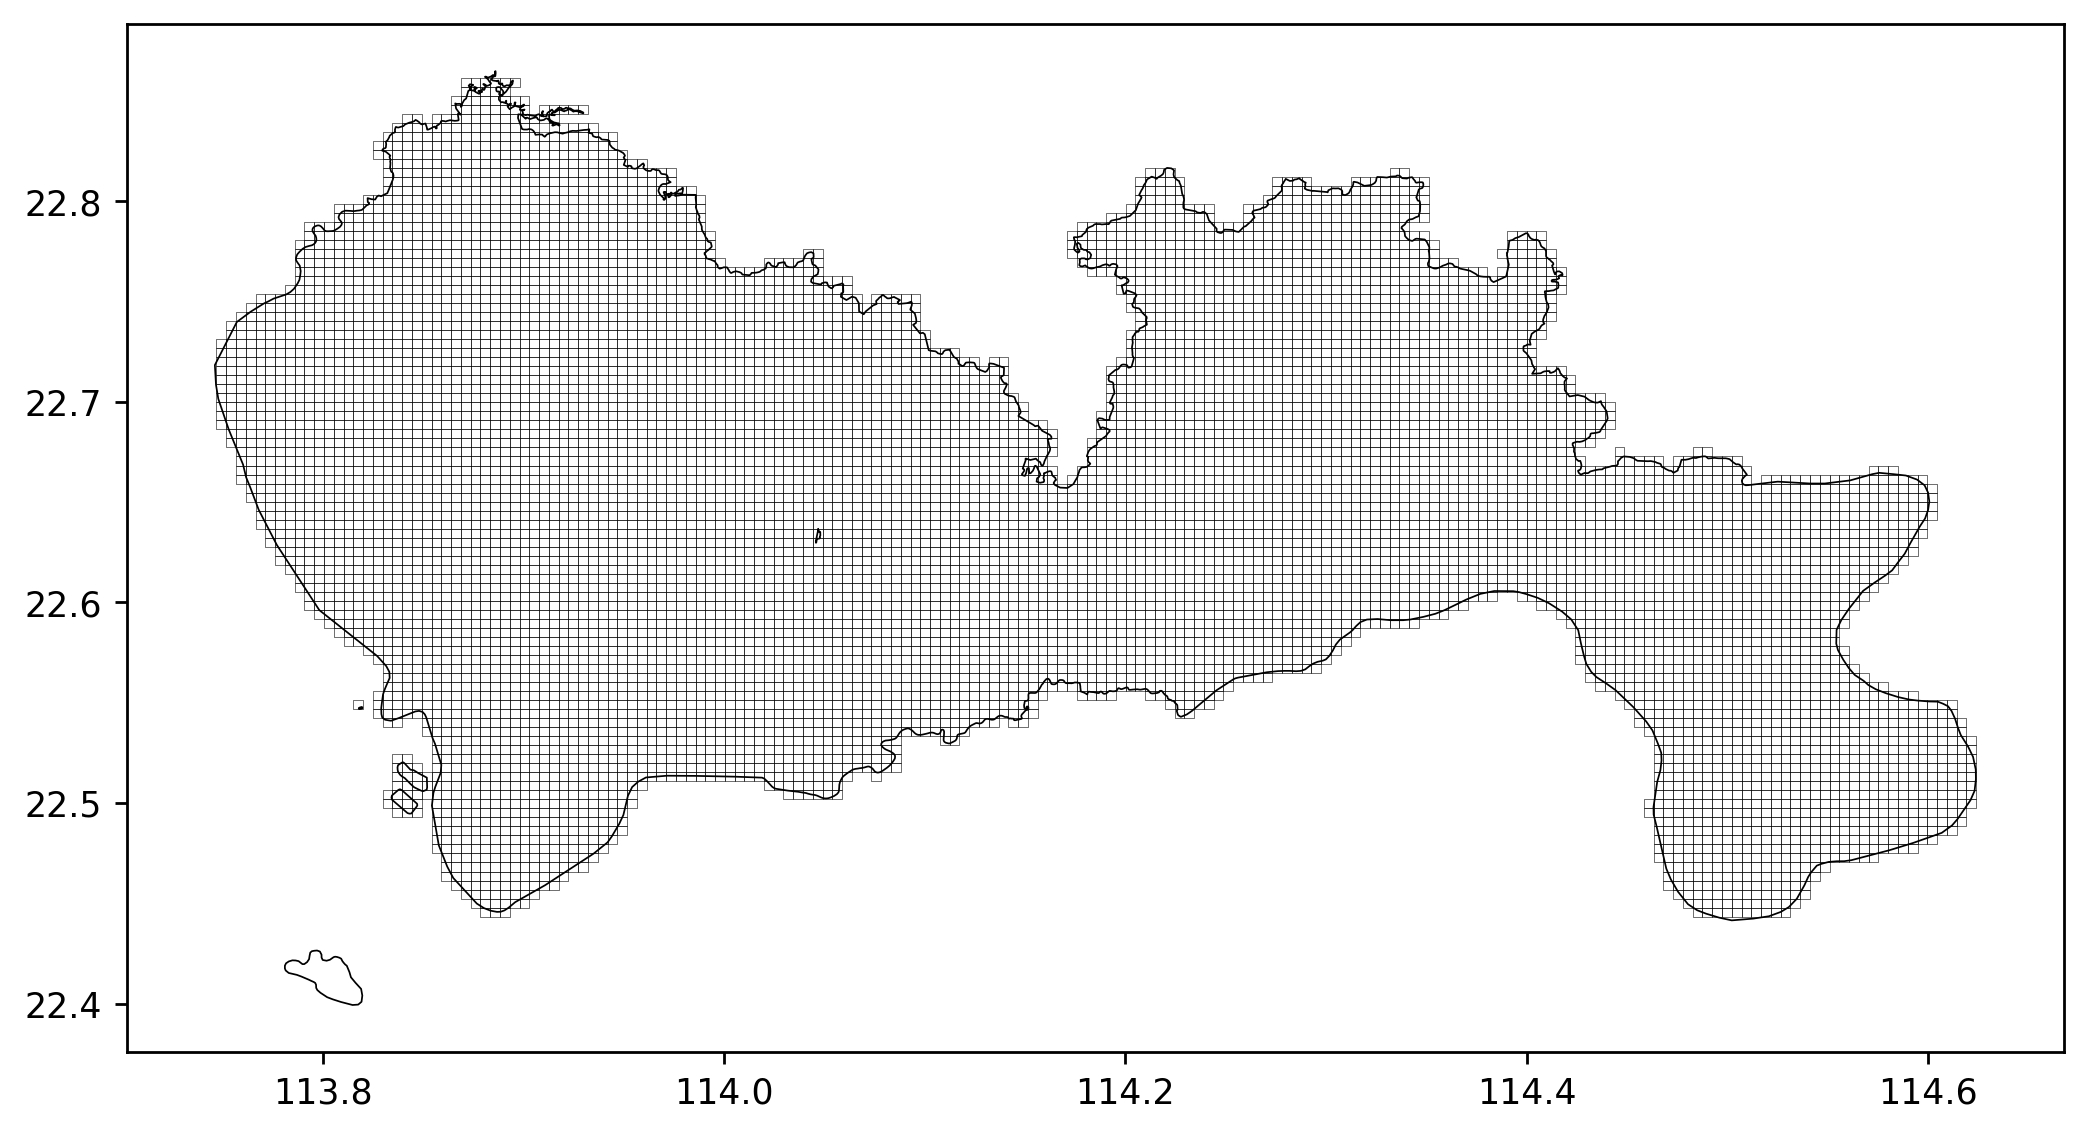

In [25]:
# 导入绘图包
import matplotlib as mpl
import matplotlib.pyplot as plt

fig     = plt.figure(1,(10,8),dpi = 250)    
ax      = plt.subplot(111)
plt.sca(ax) # 将 ax 设置为当前活动的默认坐标系

# 把刚才生成的栅格在ax上绘制
grid.plot(ax =ax,edgecolor = (0,0,0,0.8),facecolor = (0,0,0,0),linewidths=0.2)
# ax=ax：指定将栅格绘制到我们刚才创建的ax坐标系上，实现图层叠加
# edgecolor = (0,0,0,0.8)：栅格的边框颜色。(0,0,0)对应 RGB 黑色，末尾的0.8是透明度（alpha 值，0 为完全透明，1 为完全不透明）
# facecolor = (0,0,0,0)：栅格的填充颜色。这里透明度设为 0，即完全透明不填充，只显示栅格的边框线

#把合并的行政区划变成一个geopandas，在ax上绘制
SZ_all = geopandas.GeoDataFrame(geometry=[sz.union_all()]) # 创建一个空的DataFrame
SZ_all['geometry'] = [sz.union_all()]
SZ_all.plot(ax = ax,edgecolor = (0,0,0,1),facecolor = (0,0,0,0),linewidths=0.5)

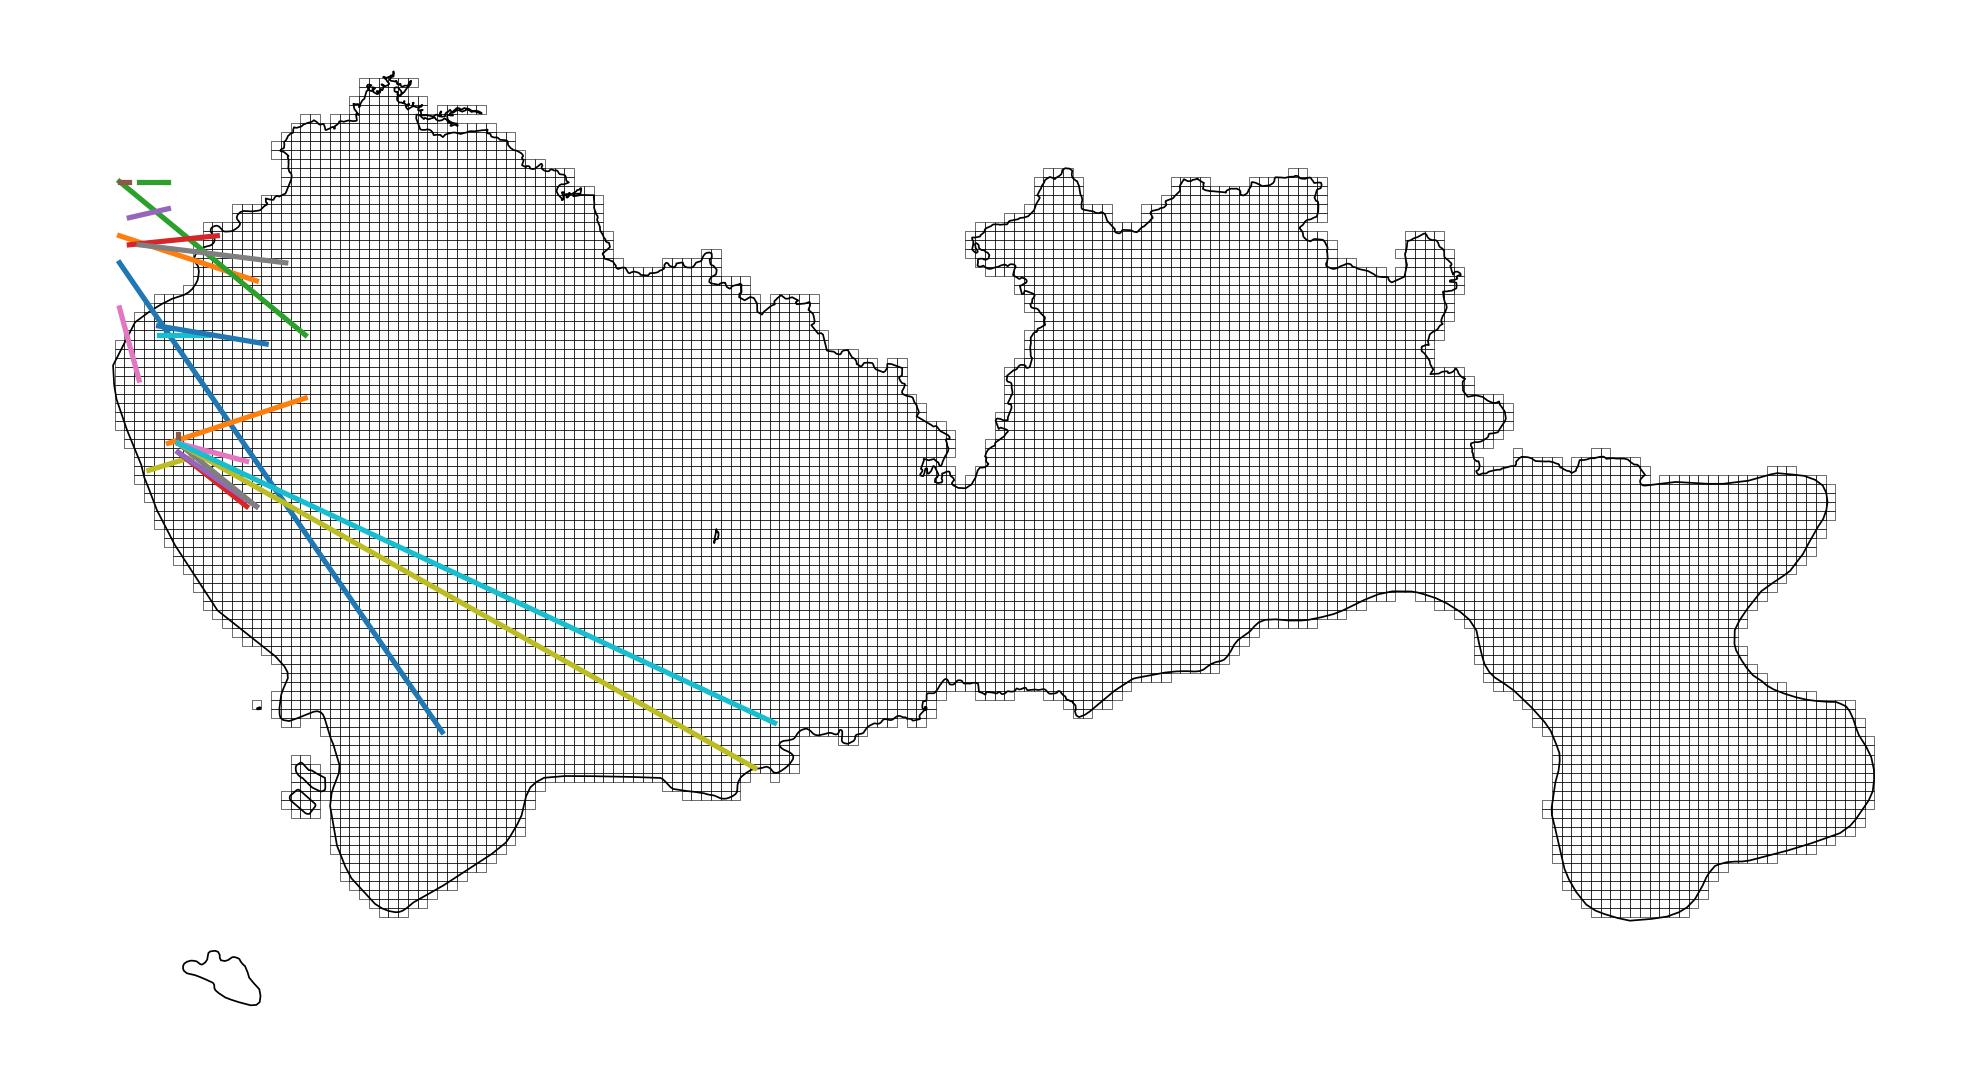

In [26]:
# 绘制前 20 条 OD 出行连线
fig     = plt.figure(1,(10,8),dpi = 250)    
ax      = plt.subplot(111)
plt.sca(ax)

# 绘制两层地理底图
grid.plot(ax =ax,edgecolor = (0,0,0,0.8),facecolor = (0,0,0,0),linewidths=0.2)
SZ_all.plot(ax = ax,edgecolor = (0,0,0,1),facecolor = (0,0,0,0),linewidths=0.5)

# 循环逐行绘制 OD 连线（核心逻辑）
for i in range(len(Topod)):

    # 把第 i 次出行的起点和终点，用直线连接起来（第一个列表放 x 坐标（经度），第二个列表放 y 坐标（纬度），就会自动连接两点成线）
    plt.plot([Topod['SHBLON'].iloc[i],Topod['EHBLON'].iloc[i]],[Topod['SHBLAT'].iloc[i],Topod['EHBLAT'].iloc[i]])


#不显示坐标轴
plt.axis('off')

plt.show()

绘制全部的OD

In [27]:
# 筛选出流量（车辆数VehicleNum）大于 10 的 OD 对，并用.copy()生成独立副本
OD1 = OD[OD['VehicleNum']>10].copy()

# 再按`VehicleNum`从小到大升序排列（使小流量 OD 先画在最底部，大流量 OD 后画在最上层，这样大流量的线条不会被小流量盖住，视觉层级更合理）
OD1 = OD1.sort_values(by = 'VehicleNum')

# 计算起点栅格的中心点经纬度
OD1['SHBLON'] = OD1['SLONCOL'] * deltaLon + (lonStart - deltaLon / 2)
OD1['SHBLAT'] = OD1['SLATCOL'] * deltaLat + (latStart - deltaLat / 2)

# 计算终点栅格的中心点经纬度
OD1['EHBLON'] = OD1['ELONCOL'] * deltaLon + (lonStart - deltaLon / 2)
OD1['EHBLAT'] = OD1['ELATCOL'] * deltaLat + (latStart - deltaLat / 2)

# 按流量分级生成线宽 linewidth
step = 5
OD1['linewidth'] = (np.array(range(len(OD1)))*step/len(OD1)).astype('int')/step+0.1
"""
1. range(len(OD1))：生成从 0 到「总行数 - 1」的连续整数，对应排序后每一行的序号；
2. *step/len(OD1)：把序号线性映射到 0 ~ step`（也就是 0~5）的区间；
3. .astype('int')：向下取整，得到 0、1、2、3、4 共 5 个整数分组；
4. /step：除以 5，将分组值归一化到 0、0.2、0.4、0.6、0.8；
5. +0.1：整体偏移 0.1，最终线宽范围为 `0.1 ~ 0.9`，共 5 档：0.1、0.3、0.5、0.7、0.9
因为数据已经按流量升序排序，所以流量越小的 OD 线宽越细，流量越大的 OD 线宽越粗
"""
OD1.head(5)


,SLONCOL,SLATCOL,ELONCOL,ELATCOL,VehicleNum,SHBLON,SHBLAT,EHBLON,EHBLAT,linewidth
960,12,40,12,39,11,113.807975,22.625453,113.807975,22.620956,0.1
104714,61,22,58,21,11,114.046733,22.544514,114.032115,22.540017,0.1
104605,61,22,12,40,11,114.046733,22.544514,113.807975,22.625453,0.1
104446,61,21,64,16,11,114.046733,22.540017,114.061351,22.517534,0.1
104400,61,21,61,17,11,114.046733,22.540017,114.046733,22.522031,0.1


绘制深圳市出租车 OD（起讫点）流量可视化专题图

绘制OD用时 1.8332884311676025 秒


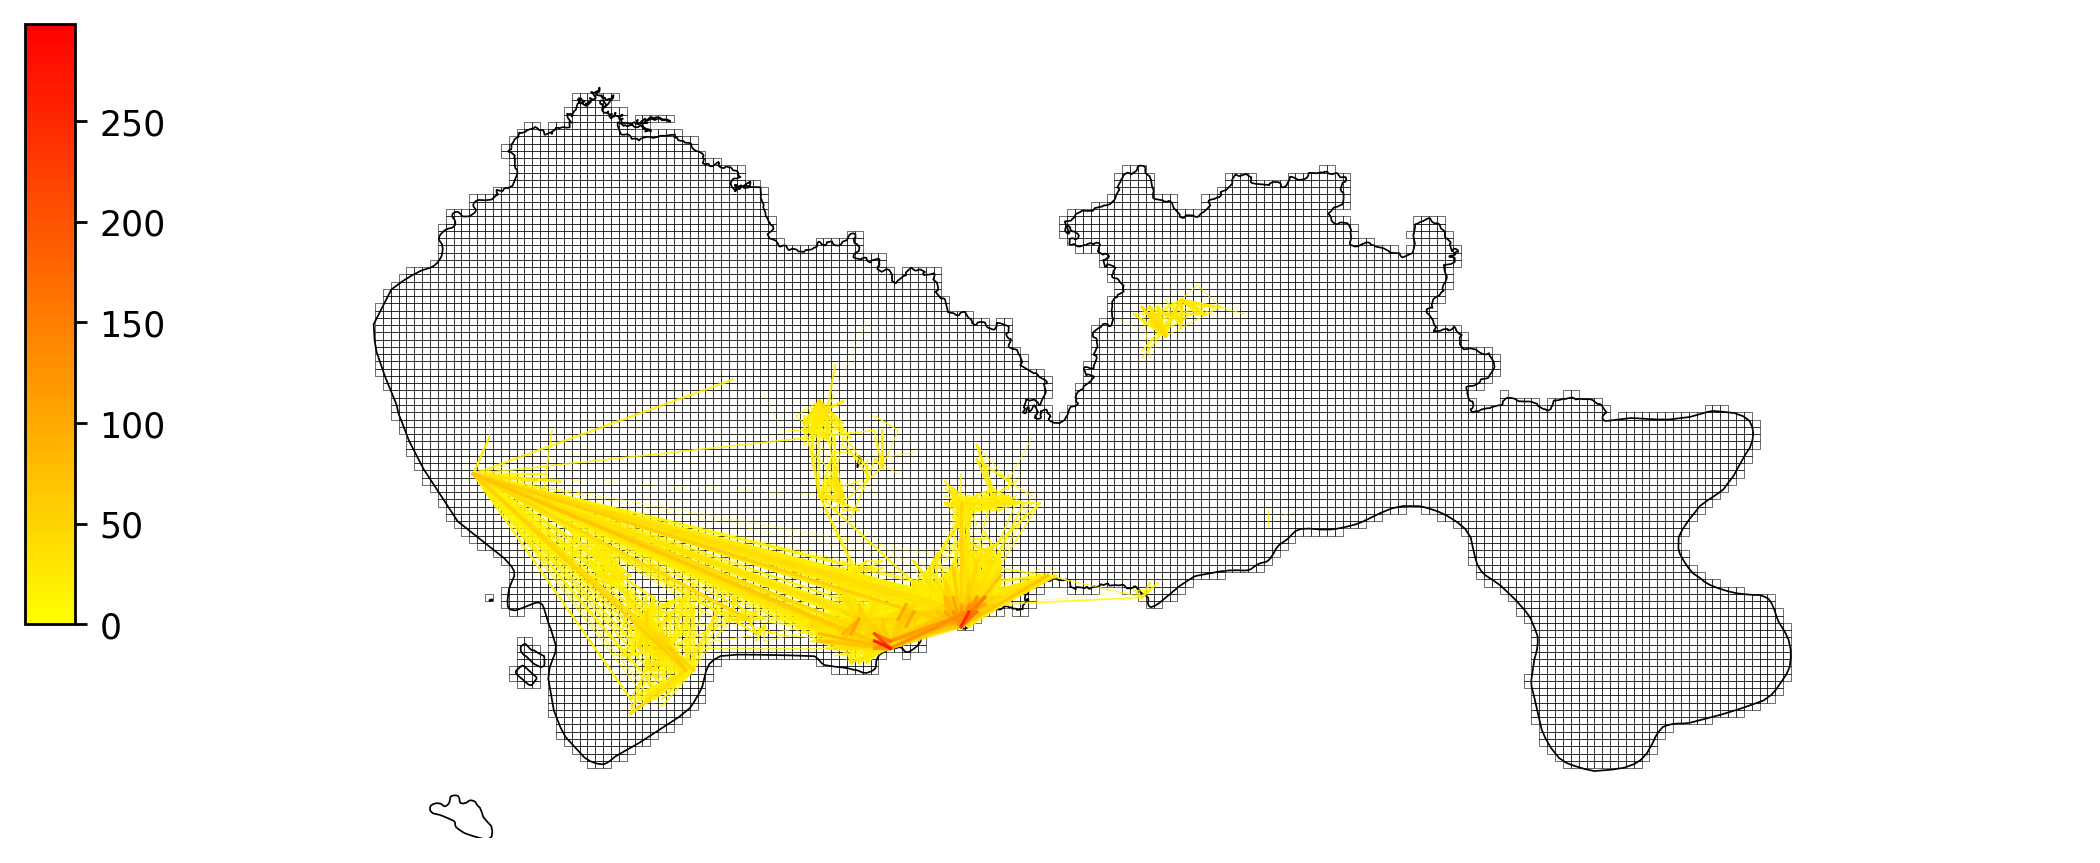

In [28]:
fig     = plt.figure(1,(10,8),dpi = 250)    
ax      = plt.subplot(111)
plt.sca(ax)

# 绘制底图图层（栅格网格 + 深圳行政边界）
grid.plot(ax = ax,edgecolor = (0,0,0,0.8),facecolor = (0,0,0,0),linewidths=0.2)

# 绘制整个深圳的范围
SZ_all.plot(ax = ax,edgecolor = (0,0,0,1),facecolor = (0,0,0,0),linewidths=0.5)

# 配置颜色映射规则（Colormap）
import matplotlib
vmax = OD['VehicleNum'].max() # 计算 OD 数据中VehicleNum（车辆数，代表 OD 流量大小）的最大值，作为颜色映射的上限
# 设定一个数值归一化工具，设定OD的colormap最大最小值，他的作用是norm(count)就会将count标准化到0-1的范围内
norm = mpl.colors.Normalize(vmin=0,vmax=vmax)

# 设定colormap的颜色
cmapname = 'autumn_r' # autumn是 matplotlib 内置的橙黄色系色板（从浅黄到橙红渐变）；后缀_r表示反转色阶，即数值越小颜色越浅、数值越大颜色越深

# matplotlib.colormaps：全局颜色映射注册表
# .get_cmap(cmapname)：输入参数 cmapname 是一个字符串，代表颜色方案的名字，你代码里传的是 'autumn_r'。
# 返回值是一个 Colormap 类型的对象，也就是我们常说的「色带 / 色阶工具」
cmap = matplotlib.colormaps.get_cmap(cmapname)

# 循环绘制OD线段
import time
timeflag = time.time() # 记录循环开始前的时间戳，用于后续统计循环绘图的总耗时
for i in range(len(OD1)): # ：遍历OD1的每一行数据，逐行绘制一条 OD 起点 - 终点的连线
    plt.plot(
        [OD1['SHBLON'].iloc[i], OD1['EHBLON'].iloc[i]],
        [OD1['SHBLAT'].iloc[i], OD1['EHBLAT'].iloc[i]],
        color = cmap(norm(OD1['VehicleNum'].iloc[i])), # 先取出当前 OD 的车辆数，用norm()归一化到 0~1 区间，再用cmap()转换成对应颜色
        linewidth = OD1['linewidth'].iloc[i], # 使用数据中预计算好的linewidth字段，流量越大线条越粗，从 “颜色 + 粗细” 两个维度强化流量大小的表达
        alpha = 0.8
    )
  
print('绘制OD用时',time.time()-timeflag,'秒')

# 图像美化和图例设置
# 不显示坐标轴
plt.axis('off')    

# 绘制一个 “不可见的虚拟图像”，用来间接生成颜色条（colorbar）
# plt.plot绘制的线条无法直接绑定颜色条；而imshow是绘制二维栅格的函数，可以直接关联 colormap 并生成颜色条
# 这里传入[[0,vmax]]是一个 1 行 2 列的数组，数值范围刚好和 OD 流量范围一致。这个图像默认会画在坐标原点附近，
# 后续调整坐标范围后会被移出视野，用户看不到它，只会用到它绑定的色条
plt.imshow([[0,vmax]], cmap=cmap)

# 在画布上手动创建一个新的小轴，专门用来放置颜色条
# 参数[left, bottom, width, height]均为相对于整个画布的比例：距离左侧 8%、底部 40% 的位置，创建一个宽 2%、高 30% 的竖长条轴
cax = plt.axes([0.08, 0.4, 0.02, 0.3])
plt.colorbar(cax=cax)

# 然后要把镜头调整回到深圳地图那，不然镜头就在imshow那里了
# 锁定深圳市的经纬度区间，把刚才绘制的 “虚拟 imshow” 挤出视野，画面只保留深圳区域的地理内容
ax.set_xlim(113.6,114.8)
ax.set_ylim(22.4,22.9)



plt.show()

更快的绘制方法

In [29]:
# 如果遍历绘制OD，绘制速度比较慢，但是，如果把DataFrame变成GeoDataFrame，然后用自带的plot函数绘制，会快很多
from shapely.geometry import LineString # 从shapely库中导入LineString（线要素）类

# 给OD1新增一列geometry，每一行对应一条 OD 的起终点连线（LineString 对象
OD1['geometry'] = OD1.apply(lambda r:LineString([[r['SHBLON'],r['SHBLAT']],[r['EHBLON'],r['EHBLAT']]]),axis = 1)
# apply是 pandas 的逐行 / 逐列批量执行函数
# axis = 1表示按行遍历：每循环一次，就把一行数据传入函数处理，最终返回和行数等长的结果
# 匿名函数lambda，r代表遍历到的某一行数据（是一个 Series 对象，可以用列名取对应值）.函数的输出是一个LineString线对象
# 最后传入 LineString 的两个坐标点（OD起点|重点栅格经纬度）

# 转换为 GeoDataFrame
OD1 = geopandas.GeoDataFrame(OD1)
# GeoDataFrame 是 geopandas 的核心数据结构，geopandas 的绘图是底层批量渲染，远快于 Python 层的逐行循环

绘制底图用时 0.9512784481048584 秒
绘制OD用时 0.15594100952148438 秒


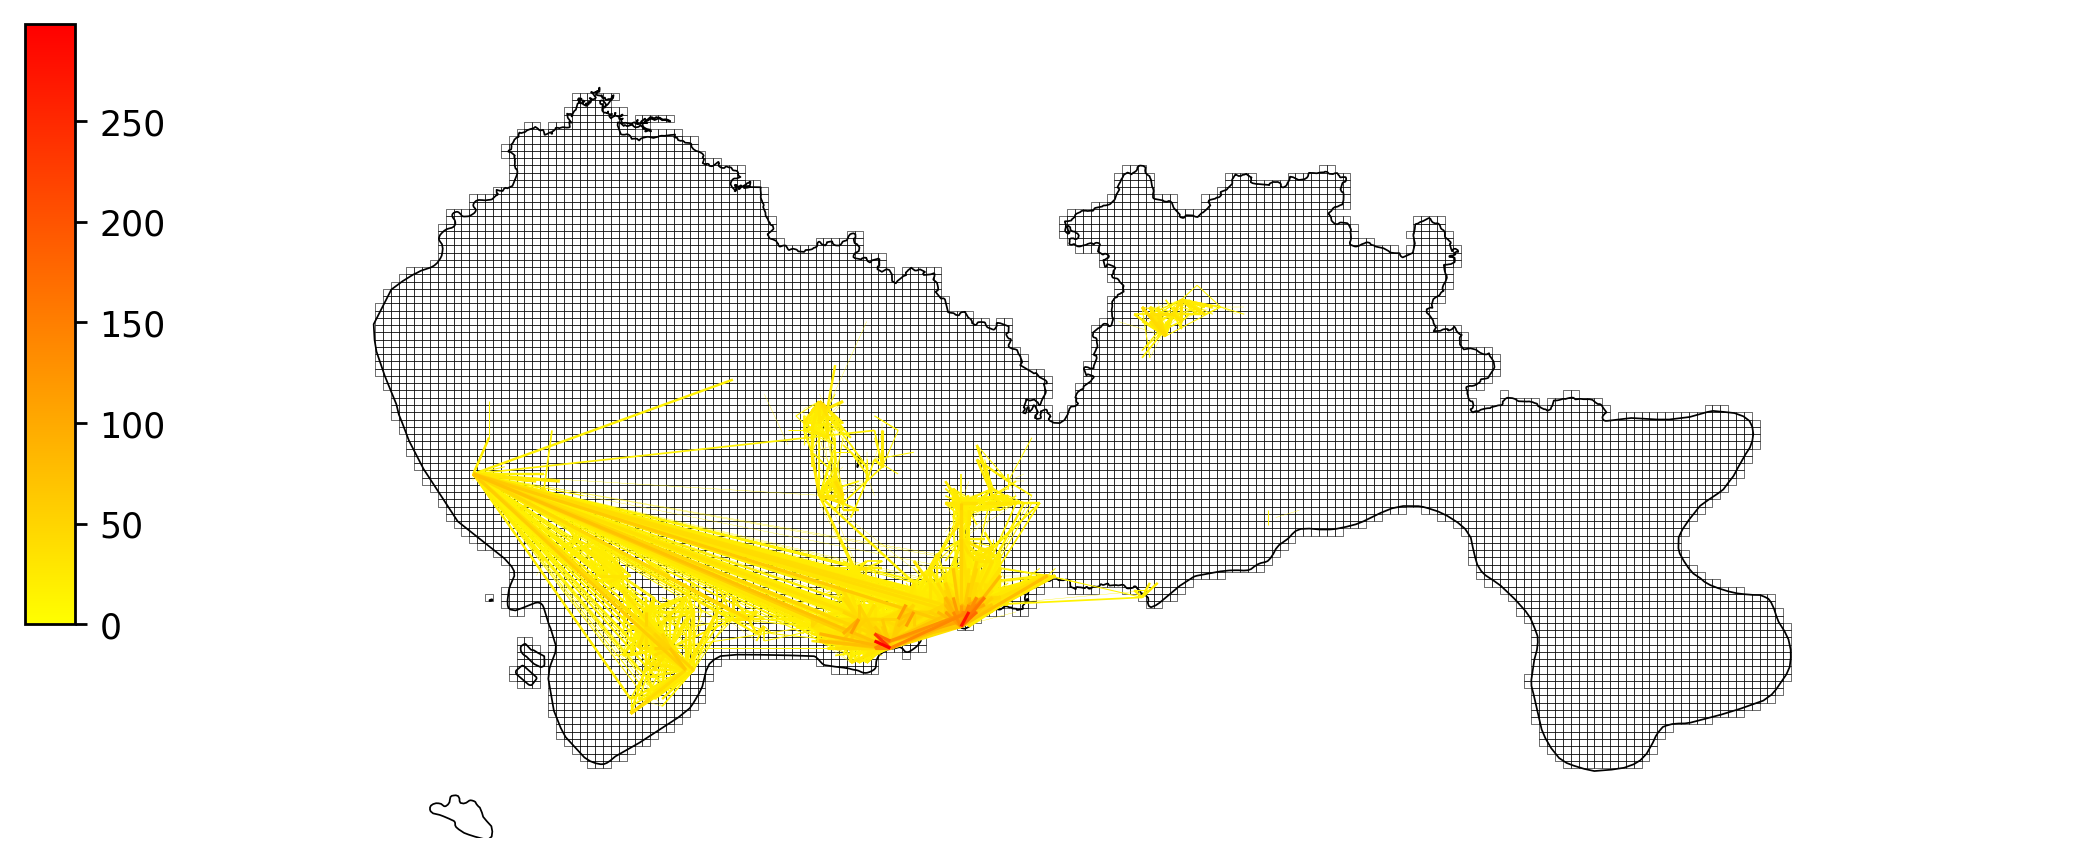

In [30]:
# 优化后的高效 OD 专题图绘制方案
fig     = plt.figure(1,(10,8),dpi = 250)    
ax      = plt.subplot(111)
plt.sca(ax)

# 计时
import time
timeflag = time.time()
# 绘制底图
grid.plot(ax = ax,edgecolor = (0,0,0,0.8),facecolor = (0,0,0,0),linewidths=0.2)
SZ_all.plot(ax = ax,edgecolor = (0,0,0,1),facecolor = (0,0,0,0),linewidths=0.5)
print('绘制底图用时',time.time()-timeflag,'秒')

# 配置颜色映射规则
# 设置colormap的数据
import matplotlib
vmax = OD['VehicleNum'].max()
cmapname = 'autumn_r'
cmap = matplotlib.colormaps[cmapname]
# 和循环版本相比，这里省略了手动创建 Normalize 归一化对象：
# geopandas 的 plot 方法可以通过 vmin/vmax 参数自动完成数值到 0-1 区间的归一化，无需手动写 norm() 转换

timeflag = time.time()

# 批量绘制 OD 线（性能优化的关键）
OD1.plot(ax = ax,column = 'VehicleNum',vmax = vmax,vmin = 0,cmap = cmap,linewidth = OD1['linewidth'])
print('绘制OD用时',time.time()-timeflag,'秒')

# 美化与图例设置
plt.axis('off')    
plt.imshow([[0,vmax]], cmap=cmap)
cax = plt.axes([0.08, 0.4, 0.02, 0.3])
plt.colorbar(cax=cax)
ax.set_xlim(113.6,114.8)
ax.set_ylim(22.4,22.9)
plt.show()

绘制栅格专题图

In [31]:
# 按起点栅格分组，统计每个起点栅格发出的总出租车流量
# 集计
Odistribution = OD.groupby(['SLONCOL','SLATCOL'])['VehicleNum'].sum().reset_index()
# groupby：pandas 的分组聚合函数，按指定列的值对数据进行分组，相同值的行会被归为同一组
# 分别以起点所在栅格的经度|维度编号，二者组合唯一标识一个起点栅格
# .sum()：对每组内的VehicleNum执行求和运算，得到每个起点栅格的总发车流量（一个带多级索引（SLONCOL、SLATCOL 为索引）的 Series）
# .reset_index()：把分组后变成行索引的SLONCOL、SLATCOL重新变回普通数据列，同时把求和结果恢复为普通列，最终得到一张标准的平整 DataFrame

In [32]:
# 将 “栅格几何数据” 和 “起点流量统计数据” 按栅格编号关联合并，将集计的结果与栅格的geopandas执行merge操作
# 关联合并栅格几何与流量数据
gridtoplot = pd.merge(grid,Odistribution.rename(columns = {'SLONCOL':'LONCOL','SLATCOL':'LATCOL'}),on = ['LONCOL','LATCOL'])
# .rename(columns = {'SLONCOL':'LONCOL','SLATCOL':'LATCOL'}) 把右表的列名改成和左表一致，让两边有统一的关联键
"""
pd.merge 是 pandas 的表关联合并函数
左表：grid —— 带 geometry 几何列的 GeoDataFrame，包含每个栅格的多边形形状和栅格编号。
右表：重命名后的 Odistribution —— 每个起点栅格的总流量统计表。
on = ['LONCOL','LATCOL']：指定用「经度编号 + 纬度编号」两列作为匹配键，只有两列值完全相等的行才会被拼接到一起。
默认采用内连接（how='inner'）：只保留两边都存在的栅格，也就是只保留 “有发车流量” 的栅格。
合并后，gridtoplot 每一行同时包含：栅格编号、栅格几何形状、对应栅格的总发车车辆数，且因为保留了 geometry 列，它依然是一个可直接绘图的 GeoDataFrame。
"""

# 统一字段命名
gridtoplot = gridtoplot.rename(columns = {'VehicleNum':'count'})

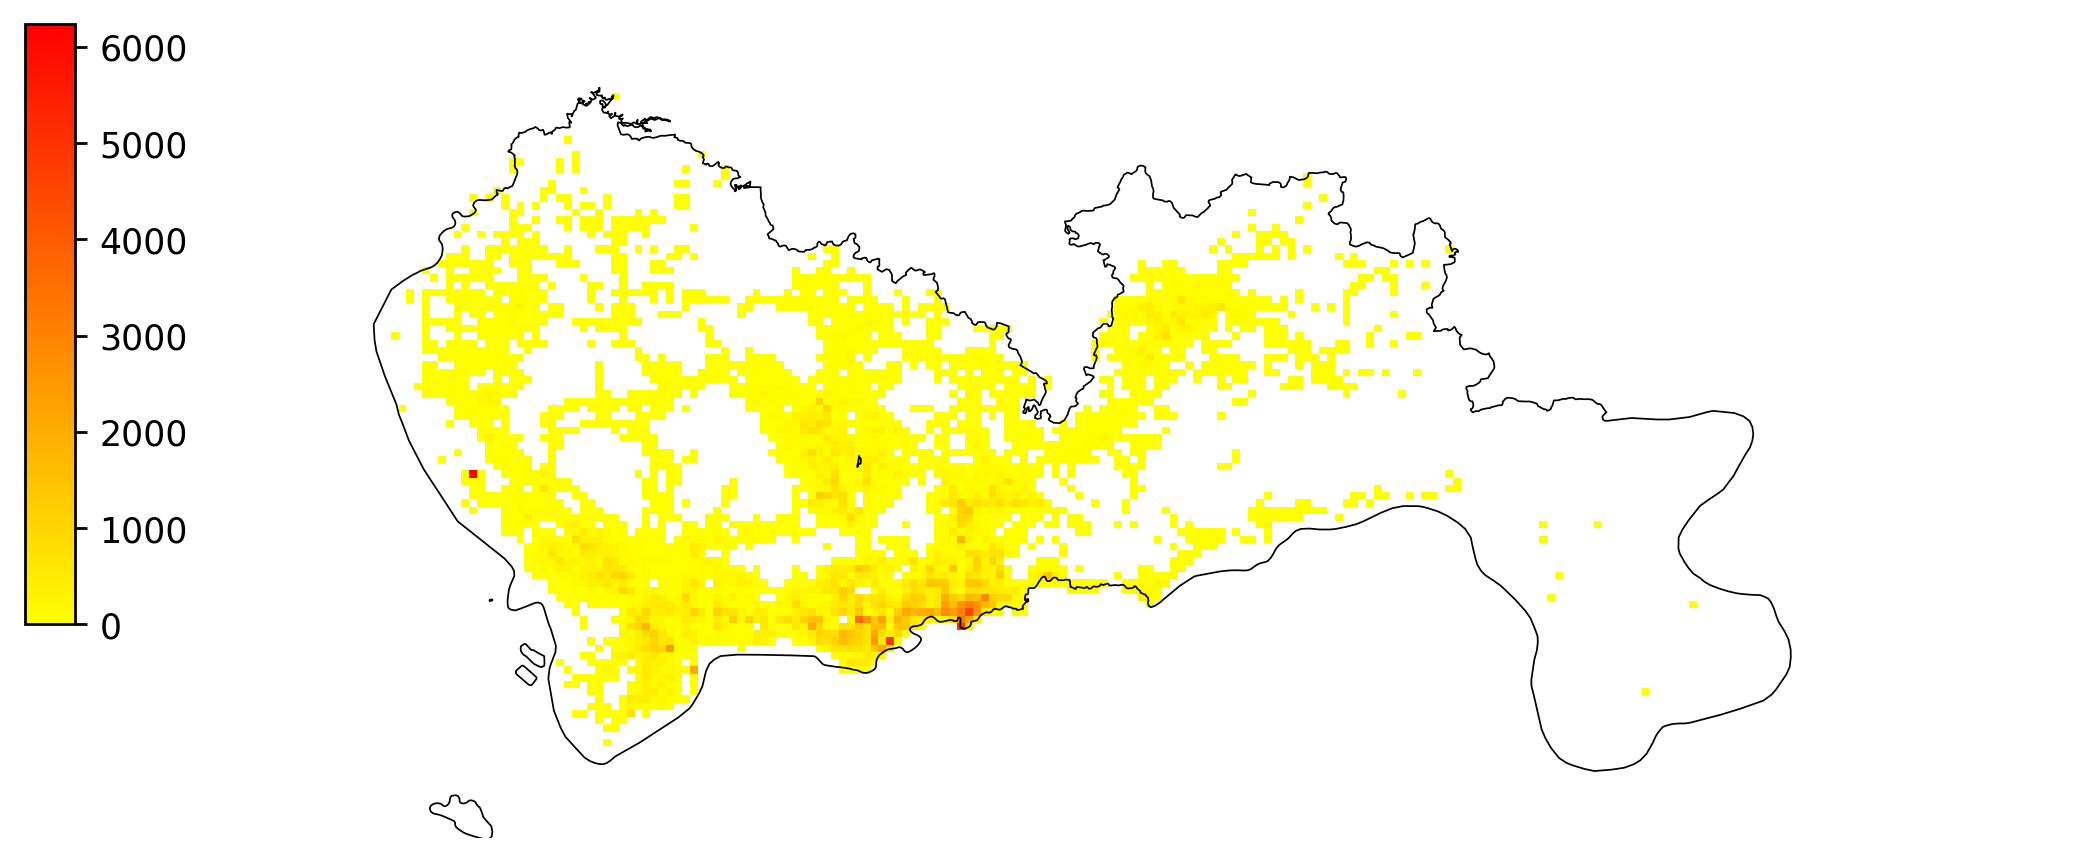

In [33]:
fig     = plt.figure(1,(10,8),dpi = 250)    
ax      = plt.subplot(111)
plt.sca(ax)

# 配置颜色映射规则
import matplotlib
vmax = gridtoplot['count'].max()
# 设定一个标准化的工具，设定OD的colormap最大最小值，他的作用是norm(count)就会将count标准化到0-1的范围内
norm = mpl.colors.Normalize(vmin=0,vmax=vmax)
# 设定colormap的颜色
cmapname = 'autumn_r'
# cmap是一个获取颜色的工具，cmap(a)会返回颜色，其中a是0-1之间的值
cmap = matplotlib.colormaps[cmapname]


# 将gridtoplot这个geodataframe进行绘制
gridtoplot.plot(ax = ax, column = 'count', vmin = 0, vmax = vmax, cmap = cmap, edgecolor = 'none')


# 绘制整个深圳的范围
SZ_all.plot(ax = ax,edgecolor = (0,0,0,1),facecolor = (0,0,0,0),linewidths=0.5)


# 不显示坐标轴
plt.axis('off')    

# 绘制假的colorbar，这是因为，我们画的OD是线，没办法直接画出来colorbar
# 所以我们在一个看不见的地方画了一个叫imshow的东西，他的范围是0到vmax
# 然后我们再对imshow添加colorbar
plt.imshow([[0,vmax]], cmap=cmap)
# 设定colorbar的大小和位置
cax = plt.axes([0.08, 0.4, 0.02, 0.3])
plt.colorbar(cax=cax)




# 然后要把镜头调整回到深圳地图那，不然镜头就在imshow那里了


ax.set_xlim(113.6,114.8)
ax.set_ylim(22.4,22.9)

plt.show()